# CSC301 Practical Implementation: Liquid Neural Networks (LTC, CfC) vs LSTM and GRU

**Supplementary prototype for the seminar paper** *"Liquid Neural Networks: Architectures, Computational Efficiency, and Emerging Applications – A Critical Review"* (The NorthCap University).

**What this notebook does.** It trains four recurrent models on a *synthetic*, irregularly sampled, multivariate time series and compares them on prediction error (MAE, RMSE), training time, inference latency, parameter count and robustness (noise, missing observations, changed sampling intervals).

| Model | Library | How time intervals are supplied |
|---|---|---|
| LTC (Liquid Time-Constant) | `ncps.torch.LTC` | `timespans=` argument |
| CfC (Closed-form Continuous-time) | `ncps.torch.CfC` | `timespans=` argument |
| LSTM | `torch.nn.LSTM` | extra input feature (the gap, `dt`) |
| GRU | `torch.nn.GRU` | extra input feature (the gap, `dt`) |

> **Important scope note.** The original paper is a *literature-based critical review* and reports no experiments. This notebook is a **new, small-scale educational prototype** built to illustrate the evaluation framework proposed in Section IV of the paper. The data are **synthetic**; nothing here is a real-world benchmark, and no result should be read as a general claim about liquid networks. All numbers are produced by running the cells below; none are pre-written.

## Cell 1 – Installation (run once)

In [1]:
# CELL 1 - Installation
# CPU-only PyTorch is enough. For a GPU build, follow the selector at https://pytorch.org first.
# In Google Colab, torch/numpy/pandas/matplotlib are pre-installed; only ncps is needed.
%pip install -q numpy pandas matplotlib torch ncps
print("Installation step finished. If pip upgraded NumPy or Torch, restart the kernel and run from Cell 2.")

Note: you may need to restart the kernel to use updated packages.
Installation step finished. If pip upgraded NumPy or Torch, restart the kernel and run from Cell 2.


## Cell 2 – Imports and environment check

In [2]:
# CELL 2 - Imports and verification
import os, time, copy, random, platform
import importlib.metadata as importlib_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown

try:
    from ncps.torch import LTC, CfC
except ImportError as err:
    raise ImportError("Could not import LTC/CfC from ncps.torch. Run Cell 1 again "
                      "(pip install ncps) and restart the kernel.") from err

def pkg_version(name):
    try:
        return importlib_metadata.version(name)
    except Exception:
        return "unknown"

print("Python        :", platform.python_version())
print("NumPy         :", np.__version__)
print("Pandas        :", pd.__version__)
print("Matplotlib    :", plt.matplotlib.__version__)
print("PyTorch       :", torch.__version__)
print("ncps          :", pkg_version("ncps"))
print("CUDA available:", torch.cuda.is_available())
print("\nAll imports OK: LTC and CfC were loaded from ncps.torch")

Python        : 3.9.6
NumPy         : 2.0.2
Pandas        : 2.3.3
Matplotlib    : 3.8.4
PyTorch       : 2.8.0
ncps          : 1.0.1
CUDA available: False

All imports OK: LTC and CfC were loaded from ncps.torch


## Cell 3 – Configuration (all experiment settings in one place)

Every hyper-parameter used by all four models is defined here, so the comparison is documented and reproducible.
Set `QUICK_MODE = True` for a fast smoke test (smaller data, fewer epochs). Use `SEEDS = [42, 43, 44]` if you want mean ± standard deviation over three training runs (takes about three times longer).

In [3]:
# CELL 3 - Configuration
QUICK_MODE = False          # True = small/fast run for testing the pipeline
SEEDS      = [42]           # model-initialisation / shuffling seeds; e.g. [42, 43, 44] for 3 runs
MAIN_SEED  = SEEDS[0]       # run used for the loss-curve and prediction plots
DATA_SEED  = 2024           # seed of the synthetic data generator (train/val/test use +0/+1/+2)

if QUICK_MODE:
    N_TRAIN, N_VAL, N_TEST, EPOCHS = 400, 100, 200, 10
else:
    N_TRAIN, N_VAL, N_TEST, EPOCHS = 1200, 300, 500, 40

SEQ_LEN    = 40             # number of prediction steps per sequence
N_FEATURES = 3              # number of input (and output) variables
HIDDEN     = 32             # hidden units for every model
BATCH_SIZE = 64
LR         = 5e-3           # Adam learning rate (same for all models)
GRAD_CLIP  = 1.0            # gradient-norm clipping (same for all models)
REGULAR_DT = 0.3            # gap used for the "regular grid" test scenario

MODELS = ["LSTM", "GRU", "LTC", "CfC"]
COLORS = {"LSTM": "#1f77b4", "GRU": "#2ca02c", "LTC": "#d62728", "CfC": "#ff7f0e", "Persistence": "#7f7f7f"}
OUT_DIR = "lnn_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync():
    # makes GPU timing honest; does nothing on CPU
    if device.type == "cuda":
        torch.cuda.synchronize()

print(f"Device: {device} | QUICK_MODE={QUICK_MODE} | seeds={SEEDS}")
print(f"Train/Val/Test sequences: {N_TRAIN}/{N_VAL}/{N_TEST} | steps per sequence: {SEQ_LEN}")
print(f"Hidden units: {HIDDEN} | epochs: {EPOCHS} | batch: {BATCH_SIZE} | lr: {LR}")

Device: cpu | QUICK_MODE=False | seeds=[42]
Train/Val/Test sequences: 1200/300/500 | steps per sequence: 40
Hidden units: 32 | epochs: 40 | batch: 64 | lr: 0.005


## Cell 4 – Synthetic dataset design

**This is a synthetic demonstration dataset, not a real-world benchmark.** It exists so that the experiment is reproducible, the sampling times are known exactly, and irregular sampling can be controlled.

**Hidden continuous signal.** Each sequence is a sample from a continuous-time process with random amplitude `A`, frequency `ω` and phase `φ`:

- `f1(t) = A · sin(ωt + φ)`
- `f2(t) = 0.6 · A · sin(2ωt + φ/2) + 0.3 · cos(0.4t)`
- `f3(t) = 0.5 · f1(t) · f2(t)` (a nonlinear interaction)

Small Gaussian observation noise (σ = 0.03) is added to the observations.

**Irregular sampling.** Gaps between observations are drawn from a clipped log-normal distribution (range 0.05–0.9 time units), so consecutive observations are unevenly spaced.

**Prediction task (next-step prediction).** At step *k* the model receives the *previous observation* `x_{k-1}` and the *elapsed time* `Δ_k = t_k − t_{k-1}`, and must predict the next observation `x_k`. Because `ω` differs per sequence, the model must use the *history* in its hidden state to infer the dynamics, and must use `Δ_k` to know how far to extrapolate.

**Time information is preserved for every model:**
- LTC and CfC receive `Δ_k` through `timespans`.
- LSTM and GRU receive `Δ_k` as a 4th input feature (so their input has 3 + 1 = 4 channels).

All models therefore see exactly the same numbers; only the *mechanism* that consumes time differs. Features are standardised with training-set statistics; `Δ` is divided by the training-set mean gap.

In [4]:
# CELL 4 - Synthetic data generator (NumPy only)
def generate_sequences(n, seq_len, seed, dt_mode="lognormal", dt_scale=1.0, obs_noise=0.03):
    # Returns X (previous obs), Y (next obs), DT (gap before each target), T (target times).
    rng = np.random.default_rng(seed)
    omega = rng.uniform(0.5, 1.5, size=(n, 1))
    phi   = rng.uniform(0.0, 2 * np.pi, size=(n, 1))
    amp   = rng.uniform(0.8, 1.5, size=(n, 1))

    shape = (n, seq_len + 1)                         # seq_len+1 observations -> seq_len (input, target) pairs
    if dt_mode == "lognormal":                       # default: irregular gaps
        gaps = np.clip(rng.lognormal(mean=np.log(0.25), sigma=0.6, size=shape), 0.05, 0.9)
    elif dt_mode == "regular":                       # evenly spaced grid
        gaps = np.full(shape, REGULAR_DT)
    elif dt_mode == "bursty":                        # mix of short and long gaps
        short = rng.uniform(0.05, 0.15, size=shape)
        long_ = rng.uniform(0.50, 0.90, size=shape)
        gaps = np.where(rng.random(shape) < 0.3, long_, short)
    else:
        raise ValueError(f"unknown dt_mode: {dt_mode}")
    gaps = gaps * dt_scale

    t  = np.cumsum(gaps, axis=1)                     # observation times (irregular)
    f1 = amp * np.sin(omega * t + phi)
    f2 = 0.6 * amp * np.sin(2 * omega * t + 0.5 * phi) + 0.3 * np.cos(0.4 * t)
    f3 = 0.5 * f1 * f2
    obs = np.stack([f1, f2, f3], axis=-1) + rng.normal(0.0, obs_noise, size=(n, seq_len + 1, 3))

    X  = obs[:, :-1, :]                              # previous observation
    Y  = obs[:, 1:, :]                               # next observation (target)
    DT = np.diff(t, axis=1)                          # elapsed time between them
    T  = t[:, 1:]                                    # time stamp of each target
    return X, Y, DT, T

# quick self-check
_X, _Y, _DT, _T = generate_sequences(4, SEQ_LEN, DATA_SEED)
print("Generator OK. Shapes -> X:", _X.shape, "| Y:", _Y.shape, "| DT:", _DT.shape)

Generator OK. Shapes -> X: (4, 40, 3) | Y: (4, 40, 3) | DT: (4, 40)


In [5]:
# CELL 5 - Build train / validation / test sets, standardise, convert to tensors
Xtr_raw, Ytr_raw, DTtr_raw, Ttr_raw = generate_sequences(N_TRAIN, SEQ_LEN, DATA_SEED)
Xva_raw, Yva_raw, DTva_raw, Tva_raw = generate_sequences(N_VAL,   SEQ_LEN, DATA_SEED + 1)
Xte_raw, Yte_raw, DTte_raw, Tte_raw = generate_sequences(N_TEST,  SEQ_LEN, DATA_SEED + 2)

# statistics from the TRAINING set only (no leakage)
feat_mean = Xtr_raw.reshape(-1, N_FEATURES).mean(axis=0)
feat_std  = Xtr_raw.reshape(-1, N_FEATURES).std(axis=0)
dt_mean   = DTtr_raw.mean()

def standardise(X, Y, DT):
    Xs  = ((X - feat_mean) / feat_std).astype(np.float32)
    Ys  = ((Y - feat_mean) / feat_std).astype(np.float32)
    DTs = (DT / dt_mean).astype(np.float32)
    return Xs, Ys, DTs

def inverse_features(Z):
    return Z * feat_std + feat_mean

Xtr_np, Ytr_np, DTtr_np = standardise(Xtr_raw, Ytr_raw, DTtr_raw)
Xva_np, Yva_np, DTva_np = standardise(Xva_raw, Yva_raw, DTva_raw)
Xte_np, Yte_np, DTte_np = standardise(Xte_raw, Yte_raw, DTte_raw)

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32, device=device)

Xtr, Ytr, DTtr = to_tensor(Xtr_np), to_tensor(Ytr_np), to_tensor(DTtr_np)
Xva, Yva, DTva = to_tensor(Xva_np), to_tensor(Yva_np), to_tensor(DTva_np)
Xte, Yte, DTte = to_tensor(Xte_np), to_tensor(Yte_np), to_tensor(DTte_np)

summary_data = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Sequences": [N_TRAIN, N_VAL, N_TEST],
    "Steps/sequence": [SEQ_LEN] * 3,
    "X shape": [tuple(Xtr.shape), tuple(Xva.shape), tuple(Xte.shape)],
    "DT shape": [tuple(DTtr.shape), tuple(DTva.shape), tuple(DTte.shape)],
})
display(summary_data)
print(f"Raw gap statistics (training set): mean={DTtr_raw.mean():.3f}, std={DTtr_raw.std():.3f}, "
      f"min={DTtr_raw.min():.3f}, max={DTtr_raw.max():.3f}")
print("Standardisation uses training statistics only. Gap scale (mean gap) =", round(float(dt_mean), 4))

,Split,Sequences,Steps/sequence,X shape,DT shape
0,Train,1200,40,"(1200, 40, 3)","(1200, 40)"
1,Validation,300,40,"(300, 40, 3)","(300, 40)"
2,Test,500,40,"(500, 40, 3)","(500, 40)"


Raw gap statistics (training set): mean=0.295, std=0.178, min=0.050, max=0.900
Standardisation uses training statistics only. Gap scale (mean gap) = 0.2955


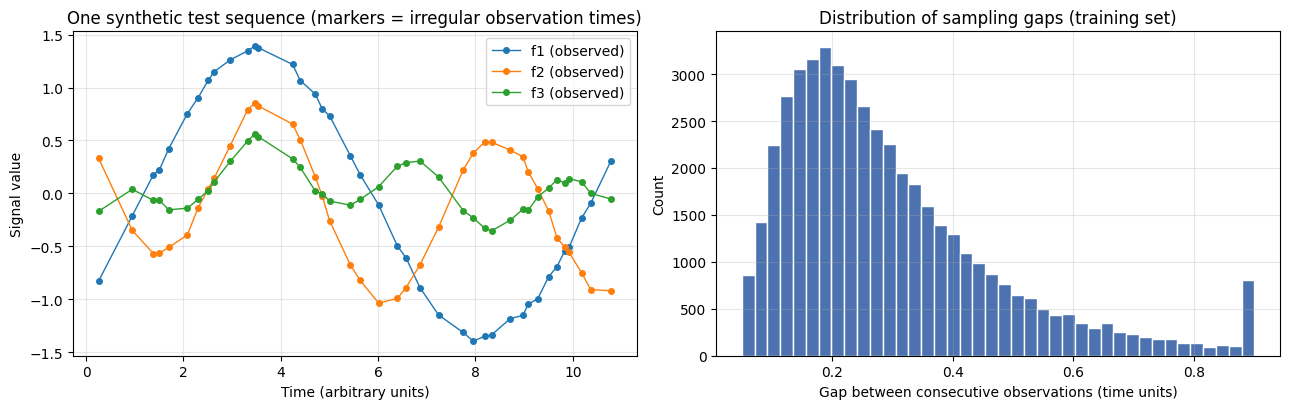

,target_time,gap_dt,prev_f1,prev_f2,prev_f3,next_f1
0,0.255,0.157,-0.893,0.539,-0.207,-0.830
1,0.948,0.693,-0.830,0.334,-0.170,-0.212
2,1.381,0.433,-0.212,-0.350,0.038,0.175
3,1.506,0.125,0.175,-0.569,-0.066,0.222
4,1.699,0.194,0.222,-0.565,-0.066,0.424
5,2.081,0.382,0.424,-0.511,-0.156,0.754
6,2.299,0.218,0.754,-0.392,-0.140,0.904
7,2.509,0.210,0.904,-0.137,-0.057,1.069


In [6]:
# CELL 6 - Look at the data: one irregularly sampled sequence and the gap distribution
idx = 0
times = Tte_raw[idx]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for k, label in enumerate(["f1", "f2", "f3"]):
    axes[0].plot(times, Yte_raw[idx][:, k], marker="o", ms=4, lw=1, label=f"{label} (observed)")
axes[0].set_title("One synthetic test sequence (markers = irregular observation times)")
axes[0].set_xlabel("Time (arbitrary units)")
axes[0].set_ylabel("Signal value")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(DTtr_raw.ravel(), bins=40, color="#4c72b0", edgecolor="white")
axes[1].set_title("Distribution of sampling gaps (training set)")
axes[1].set_xlabel("Gap between consecutive observations (time units)")
axes[1].set_ylabel("Count")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()

preview = pd.DataFrame({
    "target_time": times[:8],
    "gap_dt": DTte_raw[idx][:8],
    "prev_f1": Xte_raw[idx][:8, 0],
    "prev_f2": Xte_raw[idx][:8, 1],
    "prev_f3": Xte_raw[idx][:8, 2],
    "next_f1": Yte_raw[idx][:8, 0],
}).round(3)
display(preview)

In [7]:
# CELL 7 - A reference point: "persistence" baseline (predict that nothing changes)
# This is NOT one of the four models. It tells us how much better than "repeat the last value" each model is.
def metrics(pred, target):
    err = np.asarray(pred, dtype=np.float64) - np.asarray(target, dtype=np.float64)
    return float(np.abs(err).mean()), float(np.sqrt((err ** 2).mean()))

PERSIST_MAE, PERSIST_RMSE = metrics(Xte_np, Yte_np)
print(f"Persistence baseline on the test set (standardised units): MAE={PERSIST_MAE:.4f}, RMSE={PERSIST_RMSE:.4f}")

Persistence baseline on the test set (standardised units): MAE=0.4150, RMSE=0.5801


## Cell 8 – Model architectures

All four models share one interface: `model(x, dt) -> prediction`

| Item | Shape |
|---|---|
| `x` (previous observations) | `(batch, 40, 3)` |
| `dt` (elapsed time before each target) | `(batch, 40)` |
| output (predicted next observations) | `(batch, 40, 3)` |

Each model is **recurrent layer (hidden size 32) → `nn.Linear(32, 3)`** applied at every time step.

**Forward propagation.**
1. *LSTM / GRU:* `dt` is concatenated to `x`, giving `(batch, 40, 4)`. The recurrent layer updates its gated hidden state once per step using this 4-channel input. The linear head maps each hidden state to 3 outputs. Time enters only as an ordinary input number.
2. *LTC:* the layer keeps a state `x(t)` whose dynamics follow `dx/dt = −[1/τ + f(x, I)] ⊙ x + f(x, I) ⊙ A` (Section II-B of the paper). At each step, `timespans[:, k]` is the elapsed time over which the ODE is integrated by a numerical solver (ncps uses several fused solver sub-steps per step). The effective time constant depends on the input and state.
3. *CfC:* the layer replaces the numerical solver by an approximate closed-form update, in which a learned gating function of the elapsed time blends two candidate states. `timespans[:, k]` enters this time-dependent gate. No ODE solver loop is needed per step.

**Training procedure.** Mean-squared-error loss on all 40 steps × 3 features; Adam optimiser; same learning rate, batch size, number of epochs, gradient clipping and data order for every model; the epoch with the lowest validation loss is kept. The test set is used only for final evaluation.

> Equal hidden size does **not** mean equal capacity: the four layer types have different numbers of trainable parameters, which are reported in Cell 10 and must be kept in mind when interpreting results.

In [8]:
# CELL 8 - Model definitions (common interface: forward(x, dt))
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.rnn  = nn.LSTM(n_features + 1, hidden, batch_first=True)   # +1: dt as an input feature
        self.head = nn.Linear(hidden, n_features)
    def forward(self, x, dt):
        z = torch.cat([x, dt.unsqueeze(-1)], dim=-1)                    # (B, T, F+1)
        out, _ = self.rnn(z)
        return self.head(out)

class GRUModel(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.rnn  = nn.GRU(n_features + 1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_features)
    def forward(self, x, dt):
        z = torch.cat([x, dt.unsqueeze(-1)], dim=-1)
        out, _ = self.rnn(z)
        return self.head(out)

def run_continuous_cell(cell, x, dt, hidden):
    # Steps the ncps cell manually. dt[:, k] is passed with shape (B, 1) so it broadcasts per sample.
    # (ncps.LTC/CfC.forward squeezes timespans to (B,), which breaks broadcasting in some versions.)
    h = x.new_zeros(x.shape[0], hidden)
    outs = []
    for k in range(x.shape[1]):
        out, h = cell(x[:, k], h, dt[:, k].unsqueeze(-1))
        outs.append(out)
    return torch.stack(outs, dim=1)                                     # (B, T, hidden)

class LTCModel(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.hidden = hidden
        self.rnn  = LTC(n_features, hidden, return_sequences=True, batch_first=True)
        self.head = nn.Linear(hidden, n_features)
    def forward(self, x, dt):
        out = run_continuous_cell(self.rnn.rnn_cell, x, dt, self.hidden)  # dt acts as the elapsed time (timespans)
        return self.head(out)

class CfCModel(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.hidden = hidden
        self.rnn  = CfC(n_features, hidden, return_sequences=True, batch_first=True)
        self.head = nn.Linear(hidden, n_features)
    def forward(self, x, dt):
        out = run_continuous_cell(self.rnn.rnn_cell, x, dt, self.hidden)  # dt acts as the elapsed time (timespans)
        return self.head(out)

MODEL_CLASSES = {"LSTM": LSTMModel, "GRU": GRUModel, "LTC": LTCModel, "CfC": CfCModel}

def build_model(name):
    return MODEL_CLASSES[name](N_FEATURES, HIDDEN)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Models defined:", list(MODEL_CLASSES))

Models defined: ['LSTM', 'GRU', 'LTC', 'CfC']


In [9]:
# CELL 9 - Smoke test: shapes, batch-consistency and "does the model actually use dt?"
# Batch-consistency guards against a silent bug where per-sample time gaps are mis-broadcast across the batch.
rows = []
xb, dtb = Xtr[:48], DTtr[:48]            # 48 is deliberately different from HIDDEN (32)
for name in MODELS:
    set_seed(0)
    m = build_model(name).to(device).eval()
    with torch.no_grad():
        out_batch  = m(xb, dtb)
        out_single = m(xb[:1], dtb[:1])
        out_dt1    = m(xb, torch.ones_like(dtb))
    rows.append({
        "Model": name,
        "Output shape": tuple(out_batch.shape),
        "Batch-consistency max |diff|": float((out_batch[0] - out_single[0]).abs().max()),
        "Sensitivity to dt (max |diff|)": float((out_batch - out_dt1).abs().max()),
    })
smoke = pd.DataFrame(rows)
display(smoke)
assert all(r["Output shape"] == (48, SEQ_LEN, N_FEATURES) for r in rows), "Unexpected output shape"
bad = [r["Model"] for r in rows if r["Batch-consistency max |diff|"] > 1e-3]
if bad:
    print("WARNING: batch-consistency check failed for", bad,
          "-> see Troubleshooting (ncps timespans shape / version).")
else:
    print("Smoke test passed: correct shapes and batch-consistent outputs for all models.")

,Model,Output shape,Batch-consistency max |diff|,Sensitivity to dt (max |diff|)
0,LSTM,"(48, 40, 3)",2.980232e-08,0.058337
1,GRU,"(48, 40, 3)",2.980232e-08,0.077068
2,LTC,"(48, 40, 3)",8.940697e-08,0.102345
3,CfC,"(48, 40, 3)",1.490116e-07,0.096840


Smoke test passed: correct shapes and batch-consistent outputs for all models.


In [10]:
# CELL 10 - Trainable parameter counts
set_seed(MAIN_SEED)
param_df = pd.DataFrame({
    "Model": MODELS,
    "Trainable parameters": [count_parameters(build_model(n)) for n in MODELS],
})
display(param_df)

,Model,Trainable parameters
0,LSTM,4963
1,GRU,3747
2,LTC,4745
3,CfC,21219


## Cells 11–12 – Training

Training time is the **wall-clock time spent in the training loop only** (forward + backward + optimiser step, summed over epochs); validation passes are excluded. It depends strongly on hardware, library versions and CPU/GPU, so treat it as indicative, not absolute.

In [11]:
# CELL 11 - Prediction helper, training function
@torch.no_grad()
def predict(model, X, DT, chunk=250):
    model.eval()
    outs = [model(X[i:i + chunk], DT[i:i + chunk]) for i in range(0, X.shape[0], chunk)]
    return torch.cat(outs, dim=0)

def eval_mse(model, X, DT, Y):
    pred = predict(model, X, DT)
    return float(((pred - Y) ** 2).mean())

def train_model(name, seed, verbose=True):
    set_seed(seed)
    model = build_model(name).to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    shuffler = torch.Generator().manual_seed(seed)          # same shuffling order for every model
    n = Xtr.shape[0]
    history = {"train": [], "val": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    train_seconds = 0.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        sync(); t0 = time.perf_counter()
        perm = torch.randperm(n, generator=shuffler).to(device)
        running = 0.0
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            optimiser.zero_grad()
            loss = loss_fn(model(Xtr[idx], DTtr[idx]), Ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimiser.step()
            running += float(loss) * len(idx)
        sync(); train_seconds += time.perf_counter() - t0

        train_loss = running / n
        val_loss = eval_mse(model, Xva, DTva, Yva)
        history["train"].append(train_loss)
        history["val"].append(val_loss)
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS):
            print(f"  [{name}] epoch {epoch:3d}/{EPOCHS} | train MSE {train_loss:.5f} | val MSE {val_loss:.5f}")

    model.load_state_dict(best_state)                        # keep the best-validation weights
    return model, history, train_seconds, best_epoch

print("Training function ready.")

Training function ready.


In [12]:
# CELL 12 - Train all four models (this is the slow cell; LTC is usually the slowest)
trained, histories, train_info = {}, {}, {}
for seed in SEEDS:
    for name in MODELS:
        print(f"Training {name} (seed {seed}) ...")
        model, hist, secs, best_ep = train_model(name, seed)
        trained[(name, seed)] = model
        histories[(name, seed)] = hist
        train_info[(name, seed)] = {"train_seconds": secs, "best_epoch": best_ep}
        print(f"  -> done in {secs:.1f} s (best validation epoch: {best_ep})\n")
print("All models trained.")

Training LSTM (seed 42) ...


/var/folders/sy/bc2r5qlj6_xdfl0vrndmsh540000gn/T/ipykernel_85648/850522503.py:35: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running += float(loss) * len(idx)


  [LSTM] epoch   1/40 | train MSE 0.76861 | val MSE 0.51609
  [LSTM] epoch   5/40 | train MSE 0.15795 | val MSE 0.14618
  [LSTM] epoch  10/40 | train MSE 0.09670 | val MSE 0.08992
  [LSTM] epoch  15/40 | train MSE 0.06834 | val MSE 0.06690
  [LSTM] epoch  20/40 | train MSE 0.05471 | val MSE 0.05301
  [LSTM] epoch  25/40 | train MSE 0.04755 | val MSE 0.04571
  [LSTM] epoch  30/40 | train MSE 0.04261 | val MSE 0.04157
  [LSTM] epoch  35/40 | train MSE 0.03939 | val MSE 0.03983
  [LSTM] epoch  40/40 | train MSE 0.03733 | val MSE 0.03711
  -> done in 2.3 s (best validation epoch: 40)

Training GRU (seed 42) ...
  [GRU] epoch   1/40 | train MSE 0.69823 | val MSE 0.44646
  [GRU] epoch   5/40 | train MSE 0.15488 | val MSE 0.14210
  [GRU] epoch  10/40 | train MSE 0.09072 | val MSE 0.08390
  [GRU] epoch  15/40 | train MSE 0.06249 | val MSE 0.05941
  [GRU] epoch  20/40 | train MSE 0.04929 | val MSE 0.04808
  [GRU] epoch  25/40 | train MSE 0.04296 | val MSE 0.04277
  [GRU] epoch  30/40 | train MS

## Cell 13 – Evaluation on the clean test set

- **MAE / RMSE** are computed on standardised features (so all three variables count equally), averaged over all test sequences, steps and features.
- **Inference latency (batch = 1):** median time for one forward pass over one 40-step sequence, after warm-up (100 sequences × 3 repeats).
- **Inference time (batched):** median time per sequence when the whole test set is processed in one batch.
- **Parameters:** trainable parameters only.

In [13]:
# CELL 13 - Metrics, latency, results table
@torch.no_grad()
def measure_latency(model, X, DT, n_single=100, repeats=3, n_warm=5, n_batch_runs=5):
    model.eval()
    n_single = min(n_single, X.shape[0])
    for i in range(n_warm):
        model(X[i:i + 1], DT[i:i + 1])
    times = []
    for _ in range(repeats):
        for i in range(n_single):
            sync(); t0 = time.perf_counter()
            model(X[i:i + 1], DT[i:i + 1])
            sync(); times.append(time.perf_counter() - t0)
    single_ms = float(np.median(times)) * 1000.0
    model(X, DT)                                              # batched warm-up
    btimes = []
    for _ in range(n_batch_runs):
        sync(); t0 = time.perf_counter()
        model(X, DT)
        sync(); btimes.append(time.perf_counter() - t0)
    batched_ms_per_seq = float(np.median(btimes)) * 1000.0 / X.shape[0]
    return single_ms, batched_ms_per_seq

rows = []
for (name, seed), model in trained.items():
    pred = predict(model, Xte, DTte).cpu().numpy()
    mae, rmse = metrics(pred, Yte_np)
    lat1, latb = measure_latency(model, Xte, DTte)
    rows.append({
        "Model": name, "Seed": seed, "MAE": mae, "RMSE": rmse,
        "Train_s": train_info[(name, seed)]["train_seconds"],
        "Lat1_ms": lat1, "LatB_ms": latb,
        "Params": count_parameters(model),
        "BestEpoch": train_info[(name, seed)]["best_epoch"],
    })
results_df = pd.DataFrame(rows)

value_cols = ["MAE", "RMSE", "Train_s", "Lat1_ms", "LatB_ms", "Params", "BestEpoch"]
summary = results_df.groupby("Model")[value_cols].mean().reindex(MODELS)
summary_std = results_df.groupby("Model")[value_cols].std().reindex(MODELS)

pretty = summary.rename(columns={
    "MAE": "MAE", "RMSE": "RMSE", "Train_s": "Training time (s)",
    "Lat1_ms": "Latency, batch=1 (ms/seq)", "LatB_ms": "Inference, batched (ms/seq)",
    "Params": "Trainable params", "BestEpoch": "Best epoch"})
pretty["Trainable params"] = pretty["Trainable params"].astype(int)
print(f"RESULTS (mean over {len(SEEDS)} seed(s); test set = {N_TEST} sequences; standardised units; device = {device})")
display(pretty.round({"MAE": 4, "RMSE": 4, "Training time (s)": 1, "Latency, batch=1 (ms/seq)": 3,
                      "Inference, batched (ms/seq)": 4, "Best epoch": 1}))
if len(SEEDS) > 1:
    print("Standard deviation across seeds:")
    display(summary_std[["MAE", "RMSE", "Train_s", "Lat1_ms"]].round(4))
print(f"Persistence reference: MAE={PERSIST_MAE:.4f}, RMSE={PERSIST_RMSE:.4f}")

RESULTS (mean over 1 seed(s); test set = 500 sequences; standardised units; device = cpu)


,MAE,RMSE,Training time (s),"Latency, batch=1 (ms/seq)","Inference, batched (ms/seq)",Trainable params,Best epoch
Model,,,,,,,
LSTM,0.1330,0.1965,2.3,0.261,0.0116,4963,40.0
GRU,0.1274,0.1897,2.1,0.215,0.0079,3747,40.0
LTC,0.2089,0.2997,74.7,4.417,0.1545,4745,39.0
CfC,0.1211,0.1763,5.5,1.696,0.0193,21219,39.0


Persistence reference: MAE=0.4150, RMSE=0.5801


## Cells 14–16 – Visualisation of the main results

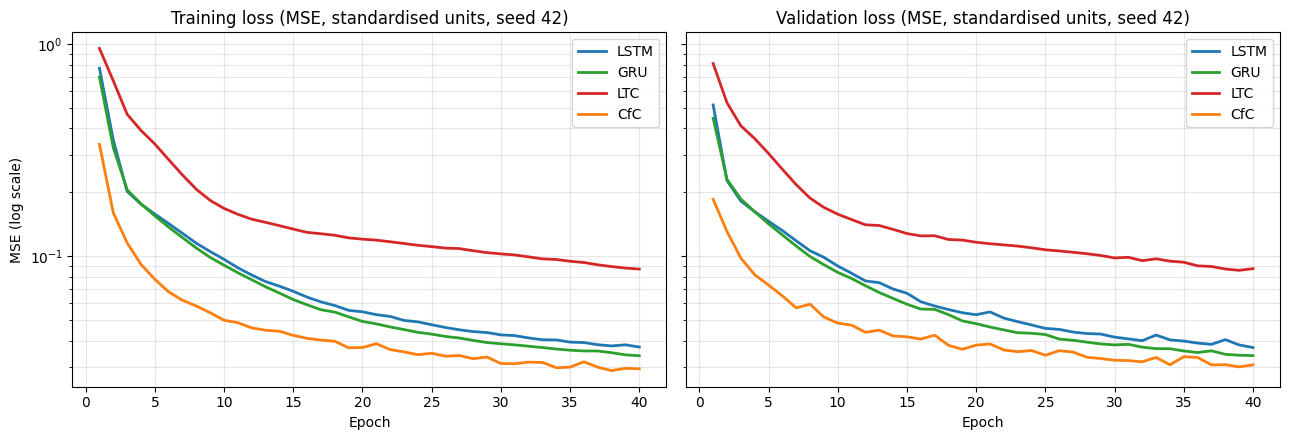

In [14]:
# CELL 14 - Training loss curves (main seed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for name in MODELS:
    h = histories[(name, MAIN_SEED)]
    epochs = np.arange(1, len(h["train"]) + 1)
    axes[0].plot(epochs, h["train"], label=name, color=COLORS[name], lw=2)
    axes[1].plot(epochs, h["val"], label=name, color=COLORS[name], lw=2)
for ax, title in zip(axes, ["Training loss", "Validation loss"]):
    ax.set_yscale("log")
    ax.set_title(f"{title} (MSE, standardised units, seed {MAIN_SEED})")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
axes[0].set_ylabel("MSE (log scale)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

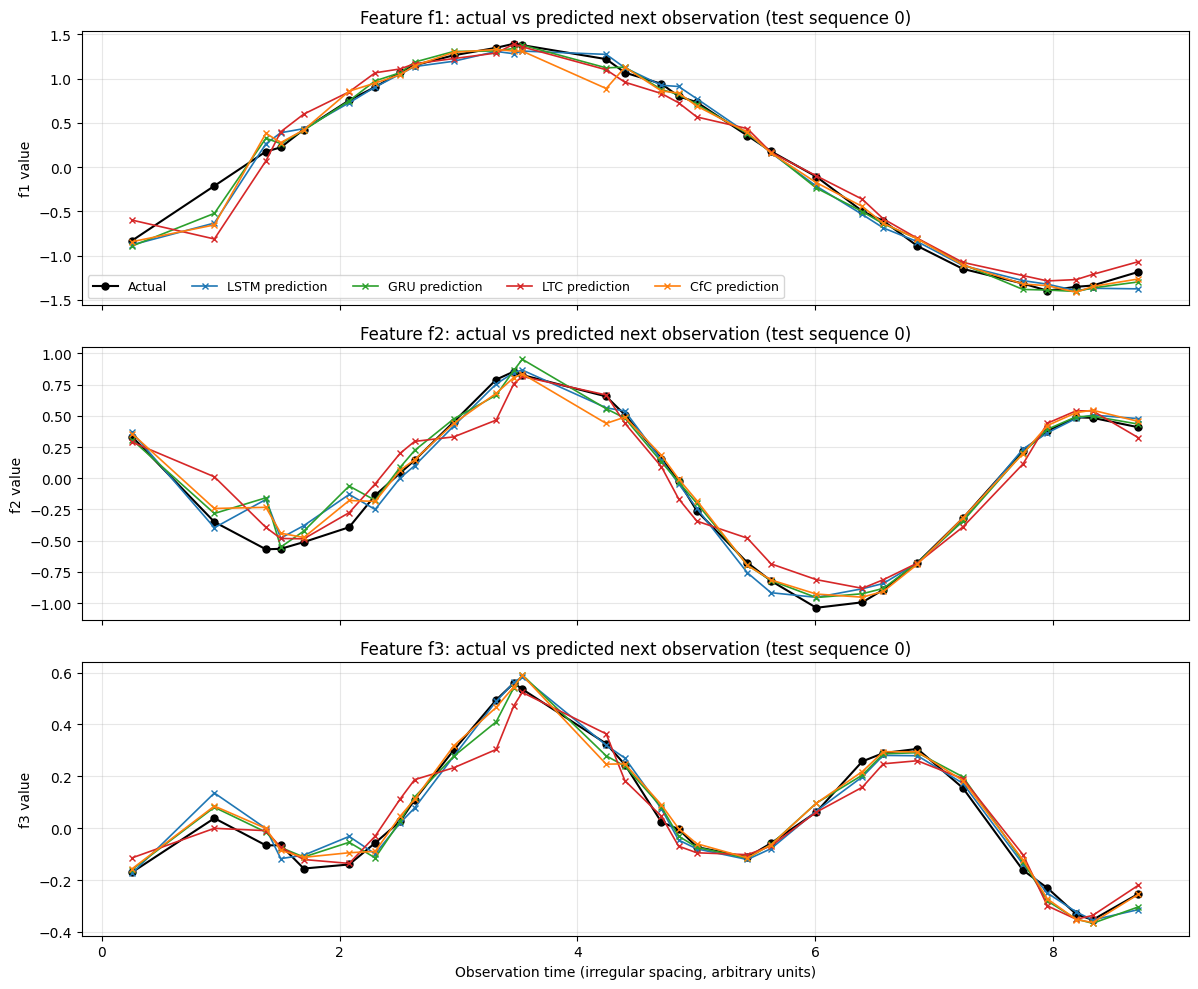

In [15]:
# CELL 15 - Actual vs predicted (one test sequence, first 30 steps, original units)
SHOW_IDX, SHOW_STEPS = 0, 30
t_axis = Tte_raw[SHOW_IDX][:SHOW_STEPS]
actual = Yte_raw[SHOW_IDX][:SHOW_STEPS]
preds = {name: inverse_features(predict(trained[(name, MAIN_SEED)], Xte[SHOW_IDX:SHOW_IDX + 1],
                                        DTte[SHOW_IDX:SHOW_IDX + 1]).cpu().numpy()[0][:SHOW_STEPS])
         for name in MODELS}

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(t_axis, actual[:, k], "k-o", ms=5, lw=1.5, label="Actual")
    for name in MODELS:
        ax.plot(t_axis, preds[name][:, k], marker="x", ms=4, lw=1.2, color=COLORS[name], label=f"{name} prediction")
    ax.set_ylabel(f"f{k + 1} value")
    ax.set_title(f"Feature f{k + 1}: actual vs predicted next observation (test sequence {SHOW_IDX})")
    ax.grid(alpha=0.3)
    if k == 0:
        ax.legend(ncol=5, fontsize=9)
axes[-1].set_xlabel("Observation time (irregular spacing, arbitrary units)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

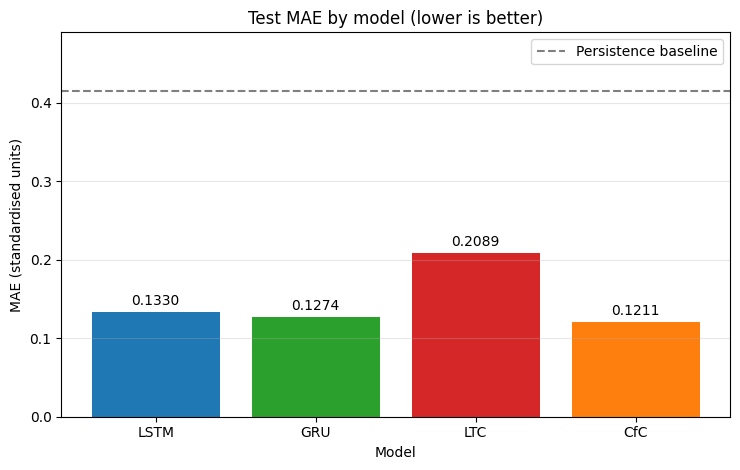

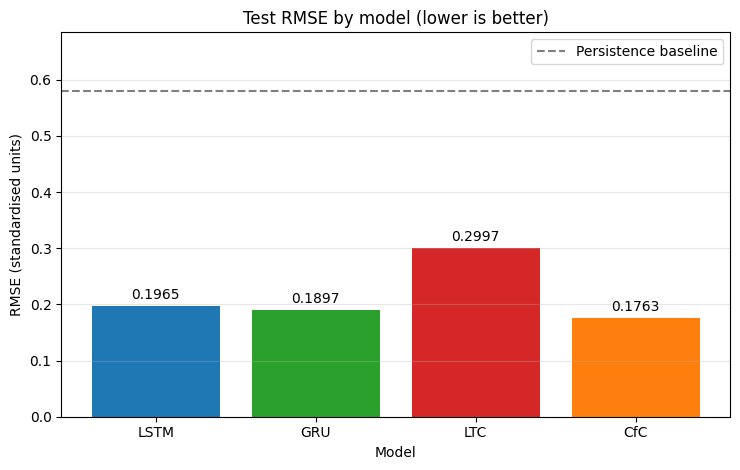

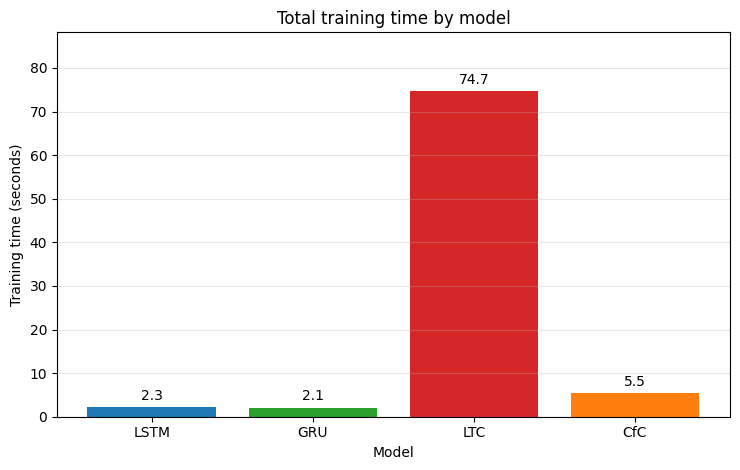

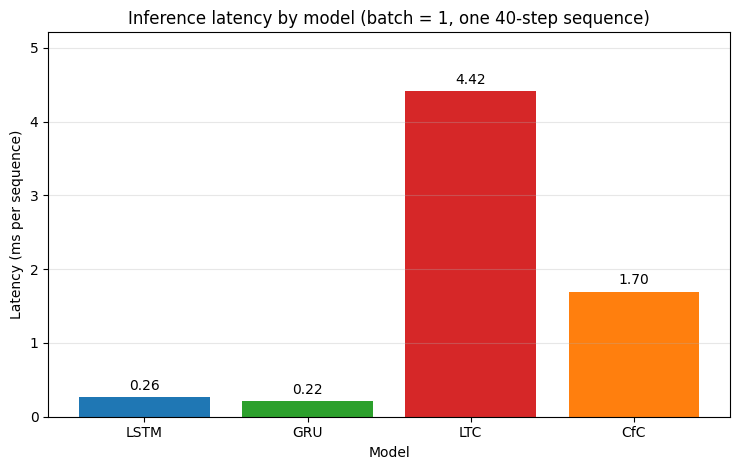

In [16]:
# CELL 16 - Model-wise comparison charts: MAE, RMSE, training time, inference latency
def bar_chart(col, title, ylabel, fname, fmt="{:.4f}", reference=None):
    means = results_df.groupby("Model")[col].mean().reindex(MODELS)
    stds = results_df.groupby("Model")[col].std().reindex(MODELS).fillna(0.0)
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    bars = ax.bar(MODELS, means.values, color=[COLORS[m] for m in MODELS],
                  yerr=stds.values if len(SEEDS) > 1 else None, capsize=4)
    ax.bar_label(bars, labels=[fmt.format(v) for v in means.values], padding=3)
    if reference is not None:
        ax.axhline(reference, ls="--", color=COLORS["Persistence"], label="Persistence baseline")
        ax.legend()
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, max(means.values.max(), reference or 0) * 1.18)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

bar_chart("MAE", "Test MAE by model (lower is better)", "MAE (standardised units)", "fig_mae", reference=PERSIST_MAE)
bar_chart("RMSE", "Test RMSE by model (lower is better)", "RMSE (standardised units)", "fig_rmse", reference=PERSIST_RMSE)
bar_chart("Train_s", "Total training time by model", "Training time (seconds)", "fig_train_time", fmt="{:.1f}")
bar_chart("Lat1_ms", "Inference latency by model (batch = 1, one 40-step sequence)", "Latency (ms per sequence)",
          "fig_latency", fmt="{:.2f}")

## Cells 17–21 – Robustness experiments

The **trained models are not retrained**; only the *test inputs* are changed. Targets are always the clean next observations (except in the sampling-interval experiment, where new test sets are generated, so the targets are new as well).

| Experiment | What is changed | Notes |
|---|---|---|
| Noise | Gaussian noise with σ ∈ {0, 0.05, 0.1, 0.2, 0.4} (standardised units) is added to the **input** observations | The same noise pattern is used for all models. |
| Missing observations | A fraction (0–50 %) of **input** observations is dropped and replaced by the last available value (last-observation-carried-forward). The first observation is never dropped. | The models receive **no missing-data mask**, so this measures degradation under *stale* inputs. It is a deliberately simple imputation, not a best practice. Time-aware skipping of steps is not implemented. |
| Sampling intervals | New test sets are generated from the same generator with gaps scaled ×0.5, ×1.5, ×2, a regular grid, and a bursty (short + long gaps) pattern | Larger gaps make the task *intrinsically harder* for every model, so compare each model against the persistence baseline and its own clean result, not only across models. |
| Time-information ablation | At test time, the true gaps are replaced by a constant, or shuffled across sequences | Shows whether each model actually uses the time information. |

The **persistence baseline** (repeat the last observation) is included in every table for context.

In [17]:
# CELL 17 - Robustness helpers + Experiment 1: input noise
def eval_arrays(X_np, DT_np, Y_np):
    Xt, DTt = to_tensor(X_np), to_tensor(DT_np)
    out = []
    for (name, seed), model in trained.items():
        mae, rmse = metrics(predict(model, Xt, DTt).cpu().numpy(), Y_np)
        out.append((name, seed, mae, rmse))
    return out

def run_scenario(scenario, levels, builder):
    records = []
    for lvl in levels:
        X_np, DT_np, Y_np = builder(lvl)
        for name, seed, mae, rmse in eval_arrays(X_np, DT_np, Y_np):
            records.append({"Scenario": scenario, "Level": lvl, "Model": name, "Seed": seed, "MAE": mae, "RMSE": rmse})
        p_mae, p_rmse = metrics(X_np, Y_np)                   # persistence on the same (possibly corrupted) inputs
        records.append({"Scenario": scenario, "Level": lvl, "Model": "Persistence", "Seed": -1, "MAE": p_mae, "RMSE": p_rmse})
    return pd.DataFrame(records)

def mae_table(df, levels):
    t = df.pivot_table(index="Level", columns="Model", values="MAE", aggfunc="mean")
    return t.reindex(levels)[MODELS + ["Persistence"]]

NOISE_LEVELS = [0.0, 0.05, 0.1, 0.2, 0.4]
def noise_builder(sigma):
    rng = np.random.default_rng(777)                          # identical noise pattern, scaled by sigma
    noise = rng.normal(0.0, 1.0, size=Xte_np.shape).astype(np.float32)
    return Xte_np + sigma * noise, DTte_np, Yte_np

rob_noise = run_scenario("Noise", NOISE_LEVELS, noise_builder)
noise_tab = mae_table(rob_noise, NOISE_LEVELS)
noise_tab.index.name = "Noise sigma"
print("Experiment 1 - MAE under input noise (standardised units)")
display(noise_tab.round(4))

Experiment 1 - MAE under input noise (standardised units)


Model,LSTM,GRU,LTC,CfC,Persistence
Noise sigma,,,,,
0.00,0.1330,0.1274,0.2089,0.1211,0.4150
0.05,0.1415,0.1371,0.2140,0.1349,0.4169
0.10,0.1643,0.1614,0.2285,0.1676,0.4234
0.20,0.2312,0.2308,0.2764,0.2573,0.4488
0.40,0.3986,0.3940,0.4021,0.4633,0.5346


In [18]:
# CELL 18 - Experiment 2: missing observations (last-observation-carried-forward, no mask given to the models)
MISSING_LEVELS = [0.0, 0.1, 0.2, 0.3, 0.5]
def missing_builder(p):
    rng = np.random.default_rng(888)
    u = rng.random(Xte_np.shape[:2])                          # same draws for every p -> nested missing sets
    drop = u < p
    drop[:, 0] = False                                        # first observation always present
    X = Xte_np.copy()
    for k in range(1, X.shape[1]):
        X[drop[:, k], k] = X[drop[:, k], k - 1]               # carry the last available value forward
    return X, DTte_np, Yte_np

rob_missing = run_scenario("Missing", MISSING_LEVELS, missing_builder)
missing_tab = mae_table(rob_missing, MISSING_LEVELS)
missing_tab.index.name = "Fraction missing"
print("Experiment 2 - MAE with missing input observations (LOCF imputation, no mask)")
display(missing_tab.round(4))

Experiment 2 - MAE with missing input observations (LOCF imputation, no mask)


Model,LSTM,GRU,LTC,CfC,Persistence
Fraction missing,,,,,
0.0,0.1330,0.1274,0.2089,0.1211,0.4150
0.1,0.1894,0.1835,0.2457,0.1831,0.4495
0.2,0.2522,0.2456,0.2924,0.2513,0.4900
0.3,0.3217,0.3153,0.3464,0.3271,0.5371
0.5,0.4926,0.4860,0.4916,0.5057,0.6588


In [19]:
# CELL 19 - Experiment 3: changed sampling intervals (new test sets, same signal generator and signal parameters)
SAMPLING_SCENARIOS = {
    "0.5x gaps":       dict(dt_scale=0.5),
    "1x (train-like)": dict(),
    "1.5x gaps":       dict(dt_scale=1.5),
    "2x gaps":         dict(dt_scale=2.0),
    "Regular grid":    dict(dt_mode="regular"),
    "Bursty gaps":     dict(dt_mode="bursty"),
}
SAMPLING_LEVELS = list(SAMPLING_SCENARIOS)

def sampling_builder(label):
    X, Y, DT, _ = generate_sequences(N_TEST, SEQ_LEN, DATA_SEED + 2, **SAMPLING_SCENARIOS[label])
    Xs, Ys, DTs = standardise(X, Y, DT)                       # SAME training-set scalers
    return Xs, DTs, Ys

# sanity check: the "1x" scenario must reproduce the original clean test set exactly
_x, _dt, _y = sampling_builder("1x (train-like)")
assert np.allclose(_x, Xte_np) and np.allclose(_dt, DTte_np), "1x scenario should equal the clean test set"

rob_sampling = run_scenario("Sampling", SAMPLING_LEVELS, sampling_builder)
sampling_tab = mae_table(rob_sampling, SAMPLING_LEVELS)
sampling_tab.index.name = "Sampling scenario"
print("Experiment 3 - MAE under changed sampling intervals")
display(sampling_tab.round(4))
mean_gaps = {k: float(np.mean(generate_sequences(50, SEQ_LEN, 1, **v)[2])) for k, v in SAMPLING_SCENARIOS.items()}
print("Mean raw gap per scenario:", {k: round(v, 3) for k, v in mean_gaps.items()})

Experiment 3 - MAE under changed sampling intervals


Model,LSTM,GRU,LTC,CfC,Persistence
Sampling scenario,,,,,
0.5x gaps,0.1252,0.1100,0.1618,0.1022,0.2310
1x (train-like),0.1330,0.1274,0.2089,0.1211,0.4150
1.5x gaps,0.2303,0.2283,0.3185,0.2037,0.5795
2x gaps,0.3494,0.3676,0.4437,0.3262,0.7152
Regular grid,0.1109,0.1088,0.1456,0.1054,0.4308
Bursty gaps,0.1782,0.1692,0.3005,0.1550,0.3895


Mean raw gap per scenario: {'0.5x gaps': 0.148, '1x (train-like)': 0.295, '1.5x gaps': 0.443, '2x gaps': 0.59, 'Regular grid': 0.3, 'Bursty gaps': 0.271}


In [20]:
# CELL 20 - Experiment 4: time-information ablation (does the model really use dt?)
ABLATION_LEVELS = ["true dt", "constant dt", "shuffled dt"]
def ablation_builder(kind):
    if kind == "true dt":
        DT = DTte_np
    elif kind == "constant dt":
        DT = np.ones_like(DTte_np)                            # = the average training gap after scaling
    else:
        order = np.random.default_rng(999).permutation(DTte_np.shape[0])
        DT = DTte_np[order]                                   # gaps from other sequences
    return Xte_np, DT, Yte_np

rob_ablation = run_scenario("TimeAblation", ABLATION_LEVELS, ablation_builder)
ablation_tab = mae_table(rob_ablation, ABLATION_LEVELS)
ablation_tab.index.name = "dt supplied to models"
print("Experiment 4 - MAE when the supplied time gaps are removed or scrambled")
display(ablation_tab.round(4))

Experiment 4 - MAE when the supplied time gaps are removed or scrambled


Model,LSTM,GRU,LTC,CfC,Persistence
dt supplied to models,,,,,
true dt,0.1330,0.1274,0.2089,0.1211,0.415
constant dt,0.2967,0.2879,0.2939,0.2826,0.415
shuffled dt,0.3752,0.3678,0.3435,0.3690,0.415


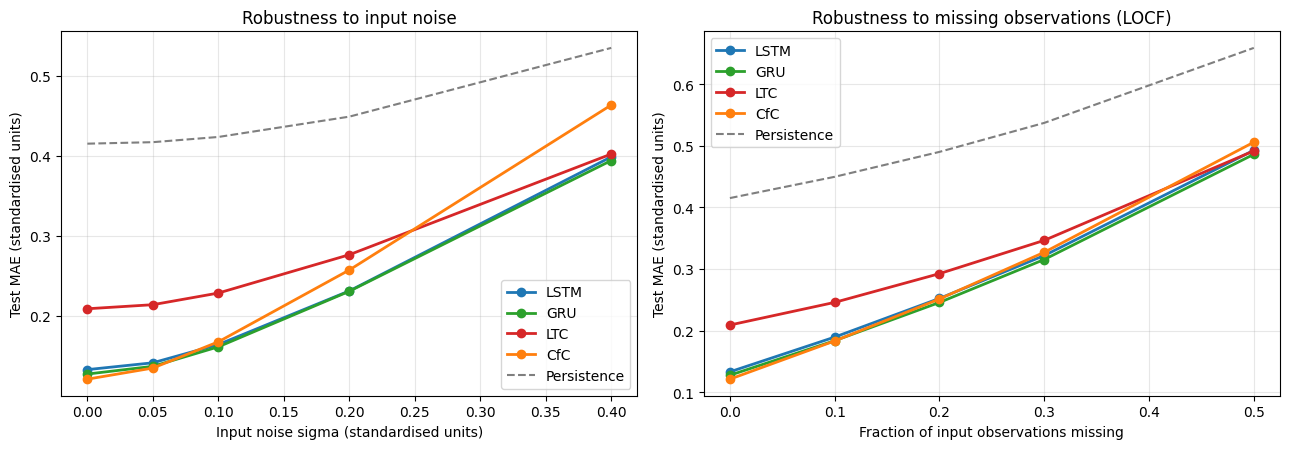

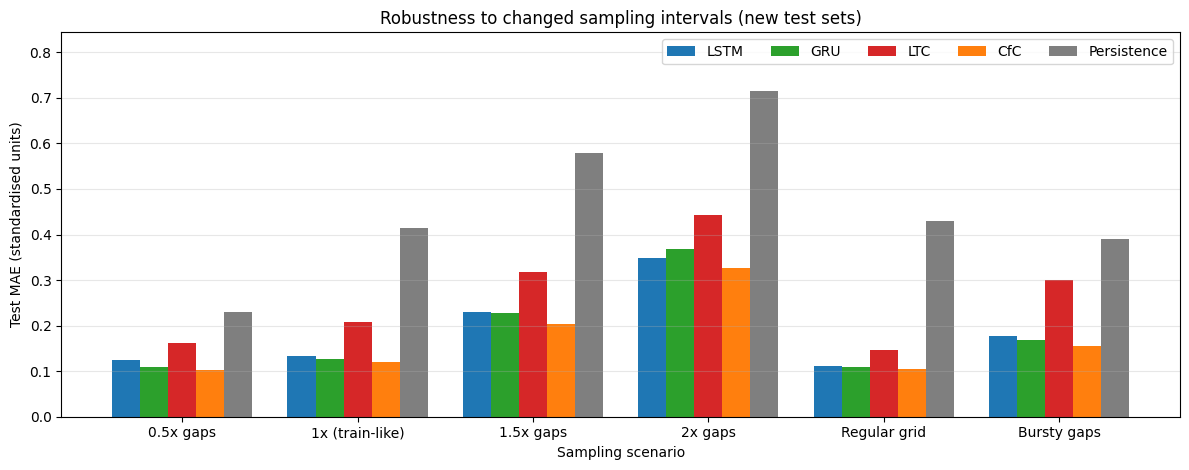

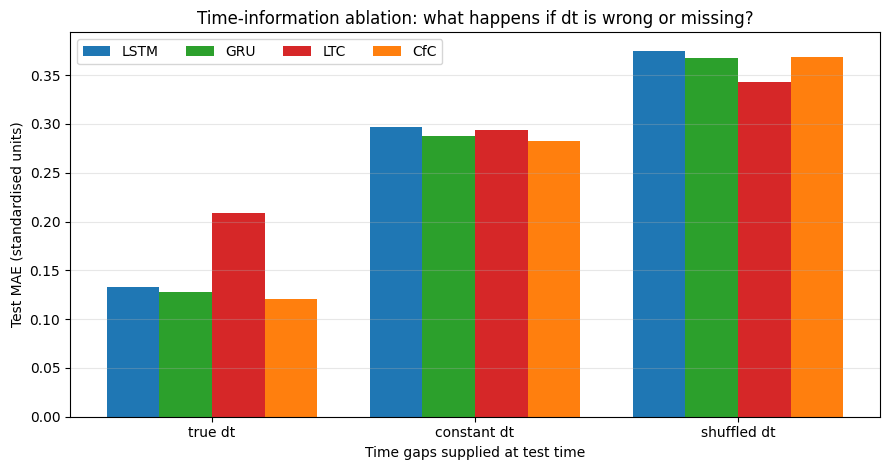

Percentage increase in MAE relative to each model's own clean-test MAE


Model,LSTM,GRU,LTC,CfC
Condition,,,,
Noise sigma=0.4,199.8,209.1,92.4,282.7
Missing 50%,270.5,281.4,135.3,317.7
2x gaps,162.8,188.4,112.4,169.4
Shuffled dt,182.2,188.6,64.4,204.8


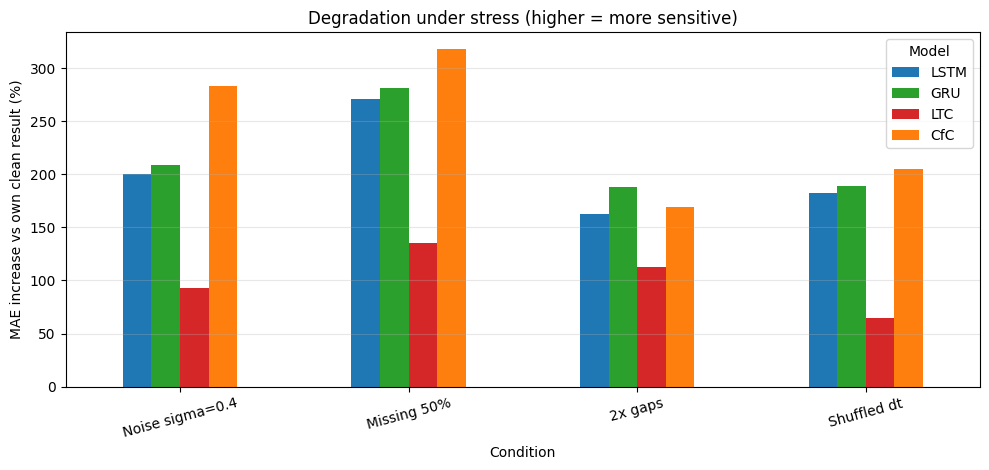

In [21]:
# CELL 21 - Robustness charts and degradation summary
def pct(new, old):
    return (new - old) / old * 100.0

# (a) line charts: MAE vs corruption level
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, tab, xlabel, title in [
    (axes[0], noise_tab, "Input noise sigma (standardised units)", "Robustness to input noise"),
    (axes[1], missing_tab, "Fraction of input observations missing", "Robustness to missing observations (LOCF)")]:
    for col in MODELS:
        ax.plot(tab.index, tab[col], marker="o", lw=2, color=COLORS[col], label=col)
    ax.plot(tab.index, tab["Persistence"], ls="--", color=COLORS["Persistence"], label="Persistence")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Test MAE (standardised units)")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_robust_noise_missing.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) grouped bars: sampling scenarios
fig, ax = plt.subplots(figsize=(12, 4.8))
width = 0.16
xpos = np.arange(len(SAMPLING_LEVELS))
for j, col in enumerate(MODELS + ["Persistence"]):
    ax.bar(xpos + (j - 2) * width, sampling_tab[col].values, width, label=col, color=COLORS[col])
ax.set_xticks(xpos); ax.set_xticklabels(SAMPLING_LEVELS)
ax.set_title("Robustness to changed sampling intervals (new test sets)")
ax.set_xlabel("Sampling scenario"); ax.set_ylabel("Test MAE (standardised units)")
ax.grid(axis="y", alpha=0.3); ax.legend(ncol=5)
ax.set_ylim(0, sampling_tab.values.max() * 1.18)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_robust_sampling.png", dpi=150, bbox_inches="tight")
plt.show()

# (c) grouped bars: time-information ablation
fig, ax = plt.subplots(figsize=(9, 4.8))
xpos = np.arange(len(ABLATION_LEVELS))
for j, col in enumerate(MODELS):
    ax.bar(xpos + (j - 1.5) * 0.2, ablation_tab[col].values, 0.2, label=col, color=COLORS[col])
ax.set_xticks(xpos); ax.set_xticklabels(ABLATION_LEVELS)
ax.set_title("Time-information ablation: what happens if dt is wrong or missing?")
ax.set_xlabel("Time gaps supplied at test time"); ax.set_ylabel("Test MAE (standardised units)")
ax.grid(axis="y", alpha=0.3); ax.legend(ncol=4)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_time_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

# (d) % change in MAE at the harshest level of each experiment (relative to the model's own clean result)
degradation = pd.DataFrame({
    f"Noise sigma={NOISE_LEVELS[-1]}": pct(noise_tab.loc[NOISE_LEVELS[-1], MODELS], noise_tab.loc[0.0, MODELS]),
    f"Missing {int(MISSING_LEVELS[-1] * 100)}%": pct(missing_tab.loc[MISSING_LEVELS[-1], MODELS], missing_tab.loc[0.0, MODELS]),
    "2x gaps": pct(sampling_tab.loc["2x gaps", MODELS], sampling_tab.loc["1x (train-like)", MODELS]),
    "Shuffled dt": pct(ablation_tab.loc["shuffled dt", MODELS], ablation_tab.loc["true dt", MODELS]),
}).T
degradation.index.name = "Condition"
print("Percentage increase in MAE relative to each model's own clean-test MAE")
display(degradation.round(1))

ax = degradation.plot(kind="bar", figsize=(10, 4.8), color=[COLORS[m] for m in MODELS], rot=15)
ax.set_title("Degradation under stress (higher = more sensitive)")
ax.set_xlabel("Condition"); ax.set_ylabel("MAE increase vs own clean result (%)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_degradation.png", dpi=150, bbox_inches="tight")
plt.show()

## Cell 22 – Results table and findings generated from the actual run

The text below is **built by code from the numbers produced in this run**, so it cannot contradict the tables. Copy it into your report and add your own interpretation. If the differences between models are small relative to the seed-to-seed variation (or if you used only one seed), treat rankings as *tentative*.

In [22]:
# CELL 22 - Auto-generated results and findings (all numbers come from the variables above)
final_table = pretty.copy()
final_table.index.name = "Model"
print("FINAL COMPARISON TABLE (clean test set)")
display(final_table.round({"MAE": 4, "RMSE": 4, "Training time (s)": 1, "Latency, batch=1 (ms/seq)": 3,
                           "Inference, batched (ms/seq)": 4, "Best epoch": 1}))

def best(col, lowest=True):
    s = summary[col]
    name = s.idxmin() if lowest else s.idxmax()
    return name, float(s[name])

def rel_gap(col):
    s = summary[col].sort_values()
    return (s.iloc[1] - s.iloc[0]) / s.iloc[0] * 100.0         # runner-up vs winner

L = []
m_name, m_val = best("MAE");     r_name, r_val = best("RMSE")
t_name, t_val = best("Train_s"); l_name, l_val = best("Lat1_ms"); b_name, b_val = best("LatB_ms")
slow_name, slow_val = best("Train_s", lowest=False)

L.append(f"**Prediction error.** The lowest test MAE was obtained by **{m_name}** ({m_val:.4f}); the lowest RMSE by **{r_name}** ({r_val:.4f}). "
         f"The runner-up was {rel_gap('MAE'):.1f}% higher in MAE"
         + (" - a gap this small should be treated as comparable performance, not a clear win." if rel_gap('MAE') < 5 else "."))
beat = [n for n in MODELS if summary.loc[n, "MAE"] < PERSIST_MAE]
L.append(f"**Reference baseline.** The persistence baseline had MAE {PERSIST_MAE:.4f}; "
         + (f"models with lower MAE than persistence: {', '.join(beat)}." if beat else "no model beat the persistence baseline in this run."))
L.append(f"**Training time.** **{t_name}** trained fastest ({t_val:.1f} s); **{slow_name}** was slowest ({slow_val:.1f} s, "
         f"{slow_val / t_val:.1f}x the fastest) on {device}.")
L.append(f"**Inference.** Lowest batch-1 latency: **{l_name}** ({l_val:.3f} ms/sequence). Lowest batched time per sequence: **{b_name}** ({b_val:.4f} ms).")
pmin = summary["Params"].idxmin(); pmax = summary["Params"].idxmax()
L.append(f"**Size.** Fewest trainable parameters: {pmin} ({int(summary.loc[pmin, 'Params'])}); most: {pmax} ({int(summary.loc[pmax, 'Params'])}). "
         "Parameter counts differ across architectures, so equal hidden size does not mean equal capacity.")

# trade-off statement
cheapest = summary["Train_s"].idxmin()
L.append(f"**Accuracy vs efficiency.** The most accurate model (MAE) was {m_name}; the fastest to train was {t_name}. "
         + ("These are the same model in this run." if m_name == t_name else
            f"{m_name} used {summary.loc[m_name, 'Train_s'] / summary.loc[t_name, 'Train_s']:.1f}x the training time of {t_name} "
            f"and reached an MAE of {summary.loc[m_name, 'MAE']:.4f} versus {summary.loc[t_name, 'MAE']:.4f}."))

L.append("**Robustness (increase in MAE relative to each model's own clean result):**")
for cond in degradation.index:
    row = degradation.loc[cond]
    L.append(f"- {cond}: " + ", ".join(f"{m} {row[m]:+.1f}%" for m in MODELS) +
             f". Smallest increase: **{row.idxmin()}**; largest: **{row.idxmax()}**.")

liquid_avg = degradation[["LTC", "CfC"]].mean(axis=1)
rnn_avg = degradation[["LSTM", "GRU"]].mean(axis=1)
L.append("**Liquid (LTC/CfC) vs gated (LSTM/GRU) sensitivity, averaged by condition:** "
         + "; ".join(f"{c}: liquid {liquid_avg[c]:+.1f}% vs gated {rnn_avg[c]:+.1f}%" for c in degradation.index) + ".")

if len(SEEDS) == 1:
    L.append("**Caution.** Only one training seed was used. Small differences between models may be due to random initialisation; "
             "rerun with `SEEDS = [42, 43, 44]` before drawing any ranking.")
else:
    L.append(f"**Seed variation.** MAE standard deviation across seeds: "
             + ", ".join(f"{m} {summary_std.loc[m, 'MAE']:.4f}" for m in MODELS) + ". Differences smaller than this are not meaningful.")
L.append("**Scope.** These findings apply only to this synthetic dataset, these hyper-parameters, this hardware and software, and four architectures.")

display(Markdown("\n\n".join(L)))

FINAL COMPARISON TABLE (clean test set)


,MAE,RMSE,Training time (s),"Latency, batch=1 (ms/seq)","Inference, batched (ms/seq)",Trainable params,Best epoch
Model,,,,,,,
LSTM,0.1330,0.1965,2.3,0.261,0.0116,4963,40.0
GRU,0.1274,0.1897,2.1,0.215,0.0079,3747,40.0
LTC,0.2089,0.2997,74.7,4.417,0.1545,4745,39.0
CfC,0.1211,0.1763,5.5,1.696,0.0193,21219,39.0


**Prediction error.** The lowest test MAE was obtained by **CfC** (0.1211); the lowest RMSE by **CfC** (0.1763). The runner-up was 5.3% higher in MAE.

**Reference baseline.** The persistence baseline had MAE 0.4150; models with lower MAE than persistence: LSTM, GRU, LTC, CfC.

**Training time.** **GRU** trained fastest (2.1 s); **LTC** was slowest (74.7 s, 35.7x the fastest) on cpu.

**Inference.** Lowest batch-1 latency: **GRU** (0.215 ms/sequence). Lowest batched time per sequence: **GRU** (0.0079 ms).

**Size.** Fewest trainable parameters: GRU (3747); most: CfC (21219). Parameter counts differ across architectures, so equal hidden size does not mean equal capacity.

**Accuracy vs efficiency.** The most accurate model (MAE) was CfC; the fastest to train was GRU. CfC used 2.6x the training time of GRU and reached an MAE of 0.1211 versus 0.1274.

**Robustness (increase in MAE relative to each model's own clean result):**

- Noise sigma=0.4: LSTM +199.8%, GRU +209.1%, LTC +92.4%, CfC +282.7%. Smallest increase: **LTC**; largest: **CfC**.

- Missing 50%: LSTM +270.5%, GRU +281.4%, LTC +135.3%, CfC +317.7%. Smallest increase: **LTC**; largest: **CfC**.

- 2x gaps: LSTM +162.8%, GRU +188.4%, LTC +112.4%, CfC +169.4%. Smallest increase: **LTC**; largest: **GRU**.

- Shuffled dt: LSTM +182.2%, GRU +188.6%, LTC +64.4%, CfC +204.8%. Smallest increase: **LTC**; largest: **CfC**.

**Liquid (LTC/CfC) vs gated (LSTM/GRU) sensitivity, averaged by condition:** Noise sigma=0.4: liquid +187.6% vs gated +204.4%; Missing 50%: liquid +226.5% vs gated +275.9%; 2x gaps: liquid +140.9% vs gated +175.6%; Shuffled dt: liquid +134.6% vs gated +185.4%.

**Caution.** Only one training seed was used. Small differences between models may be due to random initialisation; rerun with `SEEDS = [42, 43, 44]` before drawing any ranking.

**Scope.** These findings apply only to this synthetic dataset, these hyper-parameters, this hardware and software, and four architectures.

In [23]:
# CELL 23 - Save all tables (figures were saved as they were drawn)
results_df.to_csv(f"{OUT_DIR}/results_per_run.csv", index=False)
final_table.to_csv(f"{OUT_DIR}/results_summary.csv")
for name, tab in [("noise", noise_tab), ("missing", missing_tab), ("sampling", sampling_tab),
                  ("time_ablation", ablation_tab), ("degradation_pct", degradation)]:
    tab.to_csv(f"{OUT_DIR}/robustness_{name}.csv")
print("Saved files in ./" + OUT_DIR + ":")
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Saved files in ./lnn_outputs:
   fig_actual_vs_predicted.png
   fig_dataset_overview.png
   fig_degradation.png
   fig_latency.png
   fig_mae.png
   fig_rmse.png
   fig_robust_noise_missing.png
   fig_robust_sampling.png
   fig_time_ablation.png
   fig_train_time.png
   fig_training_loss.png
   results_per_run.csv
   results_summary.csv
   robustness_degradation_pct.csv
   robustness_missing.csv
   robustness_noise.csv
   robustness_sampling.csv
   robustness_time_ablation.csv


## Academic limitations (state these in your report and viva)

1. **The dataset is synthetic.** It is a controlled demonstration and not a real-world benchmark; conclusions do not transfer automatically to robotics, healthcare or finance data.
2. **Small-scale educational prototype.** Small data, short training, one hidden size, no hyper-parameter search per model, and (by default) one random seed.
3. **Only four architectures** are implemented: LTC, CfC, LSTM, GRU.
4. **Not implemented:** S4, Liquid-S4, Neural ODE, Latent ODE and CTRNN-Transformer, although they are discussed in the paper.
5. **No claim of universal superiority.** This experiment cannot show that liquid networks are better or worse than gated RNNs in general.
6. **Results depend on hardware, software versions, hyper-parameters and dataset design.** Training time and latency especially vary between machines; they were measured on the machine that runs this notebook.
7. **Design choices that affect fairness:** LSTM/GRU receive time as an extra feature whereas LTC/CfC receive it through `timespans`; parameter counts differ; the missing-data experiment uses simple LOCF without a mask; larger sampling gaps make the task intrinsically harder.
8. **Relation to the paper.** The seminar paper is a literature-based critical review and reports no experiments. This notebook is a supplementary prototype of the evaluation framework proposed in the paper, not an experiment that was part of it.